### Spectra-Scope Quick Start
Welcome, user! 

Spectra-Scope is a Python toolkit designed to streamline and automate the characterization of materials using spectral data. The package provides end-to-end workflows for feature extraction, selection, and model building on spectroscopy datasets. The examples given here and in the paper are NIR, Raman, and XANES datasets, but Spectra-Scope can be used with any spectroscopy or 1D-array like data. Key features include:
 
- Automated feature engineering from raw spectra, leveraging domain-specific transformations (such as Fourier, wavelet, and polynomial features).
- Flexible pipelines for machine learning model training and evaluation, with support for various regression and classification algorithms.
- Integration of multi-modal spectral inputs from different characterization methods 
- Feature importance and downselection for model interpretability 
- Visualization tools
- Simple [API](spectrascope.matr.io) for exploratory data analysis, interpretability, and visualization.
 
Spectra-Scope is intended to help materials scientists and data analysts get rapid, reproducible insights from complex spectral measurements. This notebook goes through a quick start of Spectra-Scope, while [Example 1](example1.ipynb) and [Example 2](grapes.ipynb) walk through the case studies in the [paper](../JOSS/paper.md). 


#### 0. Imports

In [1]:
%load_ext autoreload
%autoreload 2
from spectrascope.SpectraScope import *
from spectrascope.Features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import os

from matplotlib import gridspec
plt.style.use('../ss.mplstyle')
# from dataset_property_new import * 

In [ ]:
# Check whether SmartProcessAnalytics (SPA) is installed for LCEN support.
# If not installed, LCEN training steps below will be skipped.
# See README.md for SPA installation instructions.
try:
    import SPA
    lcen_available = True
except ImportError:
    lcen_available = False
    import warnings
    warnings.warn(
        "SmartProcessAnalytics (SPA) is not installed. "
        "LCEN model training will be skipped. "
        "See README.md for installation instructions.",
        UserWarning,
    )

#### 1. Loading the data 
For the quick start, we will load Vis-NIR (visable near infrared) absorption data from the [Ebrahimi, et al](https://www.sciencedirect.com/science/article/pii/S2666154324001224) study on vineyard grapes. The target data is the degree Brixs, or total soluble solids content of the grape. 

In [2]:
NIR = np.load('../tests/test_files/grapes_example/XSF_br.npy')
br = np.load('../tests/test_files/grapes_example/br.npy')
NIR_wls = np.load('../tests/test_files/grapes_example/nir_xaxis.npy')

n, m = NIR.shape
print(f'There are {n} NIR spectra of length {m} in the dataset')
print(f'The length of the labels ({len(br)}) propertly matches this .')
print(f'We also include the x-axis for the NIR spectra, which is the photon wavelength in nanometers.')

print(f'The datasets have shapes : X : {NIR.shape}, (# samples x # wavelength points) \n y : {br.shape} (# samples) \n x-axis : {NIR_wls.shape} (# wavelength points)')

There are 172 NIR spectra of length 2151 in the dataset
The length of the labels (172) propertly matches this .
We also include the x-axis for the NIR spectra, which is the photon wavelength in nanometers.
The datasets have shapes : X : (172, 2151), (# samples x # wavelength points) 
 y : (172,) (# samples) 
 x-axis : (2151,) (# wavelength points)


Visualizing the spectra

Text(0.5, 1.0, 'All NIR Spectra')

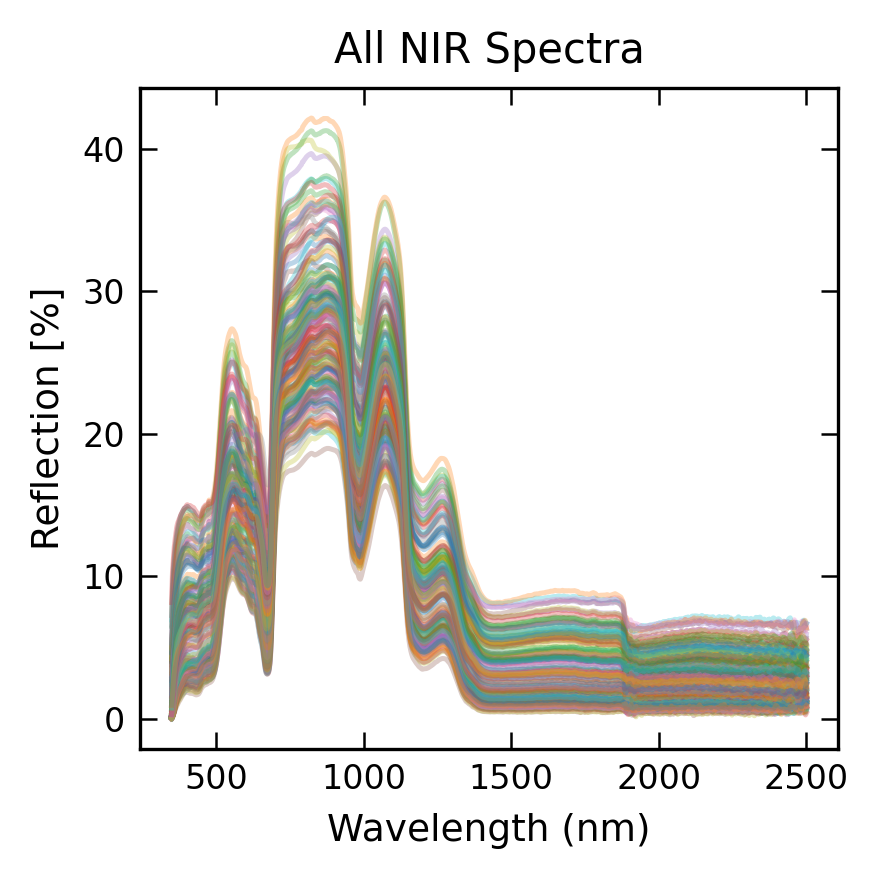

In [3]:
fig = plt.figure(figsize=(3,3))
for spec in NIR: 
    plt.plot(NIR_wls, spec, alpha=0.3)
plt.xlabel('Wavelength (nm)')
plt.ylabel('Reflection [%]');
plt.title('All NIR Spectra')

#### 2. Initialize the SpectraScope object 
We now initialize the SpectraScope object to do the feature generation and model training. First, we will use the auto_feature_generation function to automatically generate all available features. Additionally, we add the proper wavelength x-axis for the NIR data. This is necessary for some featurizations

In [4]:
ss = SpectraScope([NIR], br, specnames=['nir'], yname='br', random_seed=10)
ss.add_x_axis('nir', NIR_wls)
ss.auto_feature_generation()

saving to /examples/models, change save_path kwarg if youd like to change
generating features on all input spectra for all available features with default ranges


We can visualize examples of the features generated. 

a. ``nir_pointwise_features`` : This is the raw absorption data 

b. ``nir_polynomial_featuresll`` : Polynomials of a user-specified (default=3) degree are fit to user-specified (default 4,5,10,20) bins of the spectrum. For example, ``polynomial_featuresN``(degree=3, N=5) applied to a spectra measured from 0-10 eV will split the data into 5 bins of even energy spacing: [0,2),[2,4),[4,6),[6,8), [8,10]. The data/features that falls into each of these 2eV ranges will be fit to
a degree 3 polynomial. The 4 fit coefficients of the polynomial (a0, a1, a2, a3) are the
4 new features for each bin. Over 5 bins, this creates 20 new features. The default setting uses N=4,5,10,
and 20 bins. The result is a new 157 feature array of the input spectrum (156 fit
coefficients + the energy of the maximum feature in the spectrum). 

c. ``nir_feature_agg`` : This clustering technique performs hierarchical clustering. Each observation starts in its own cluster, and clusters are formed by computing the linkage between observations, and successively merging similar observations or clusters. The default number of clusters to generate is 15. The default metric used to compute the linkage is “euclidean” and the default linkage method is ”ward”, which minimizes the variance of the clusters being merged. 

d. ``nir_pca`` : The p principal components of a dataset are a set of orthogonal unit vectors that best describe the variance in the data. The first principal component fits a line to the direction of highest variance in the data, the second fits a line to the direction of second-highest variance, and so on. The default number of principal components is 15. 

e. ``nir_cdf`` : This is the cumulative distribution function of the data. The cumulative distribution function of a random variable X is the probability P (X ≤ x) and gives the sum of the probability of
X up to the value of x. In Spectra-Scope the spectra are treated as probability density functions where the CDF is the cumulative sum of the spectra up to the value of x.

f. ``nir_cwt`` : he CWT measures the similarity between a signal and a “mother wavelet” function which can be shifted, stretched, or compressed.6 In Spectra-Scope, the default mother wavelet is “mexh” (Mexican Hat Wavelet). The CWT provides information in the frequency- as well as time-domain. Therefore, it is useful for periodic signals which change over time, such as audio, seismic, and other signals.

g. ``nir_fft_features`` : The fast fourier transform of the spectra. 


(0.0, 1.0, 0.0, 1.0)

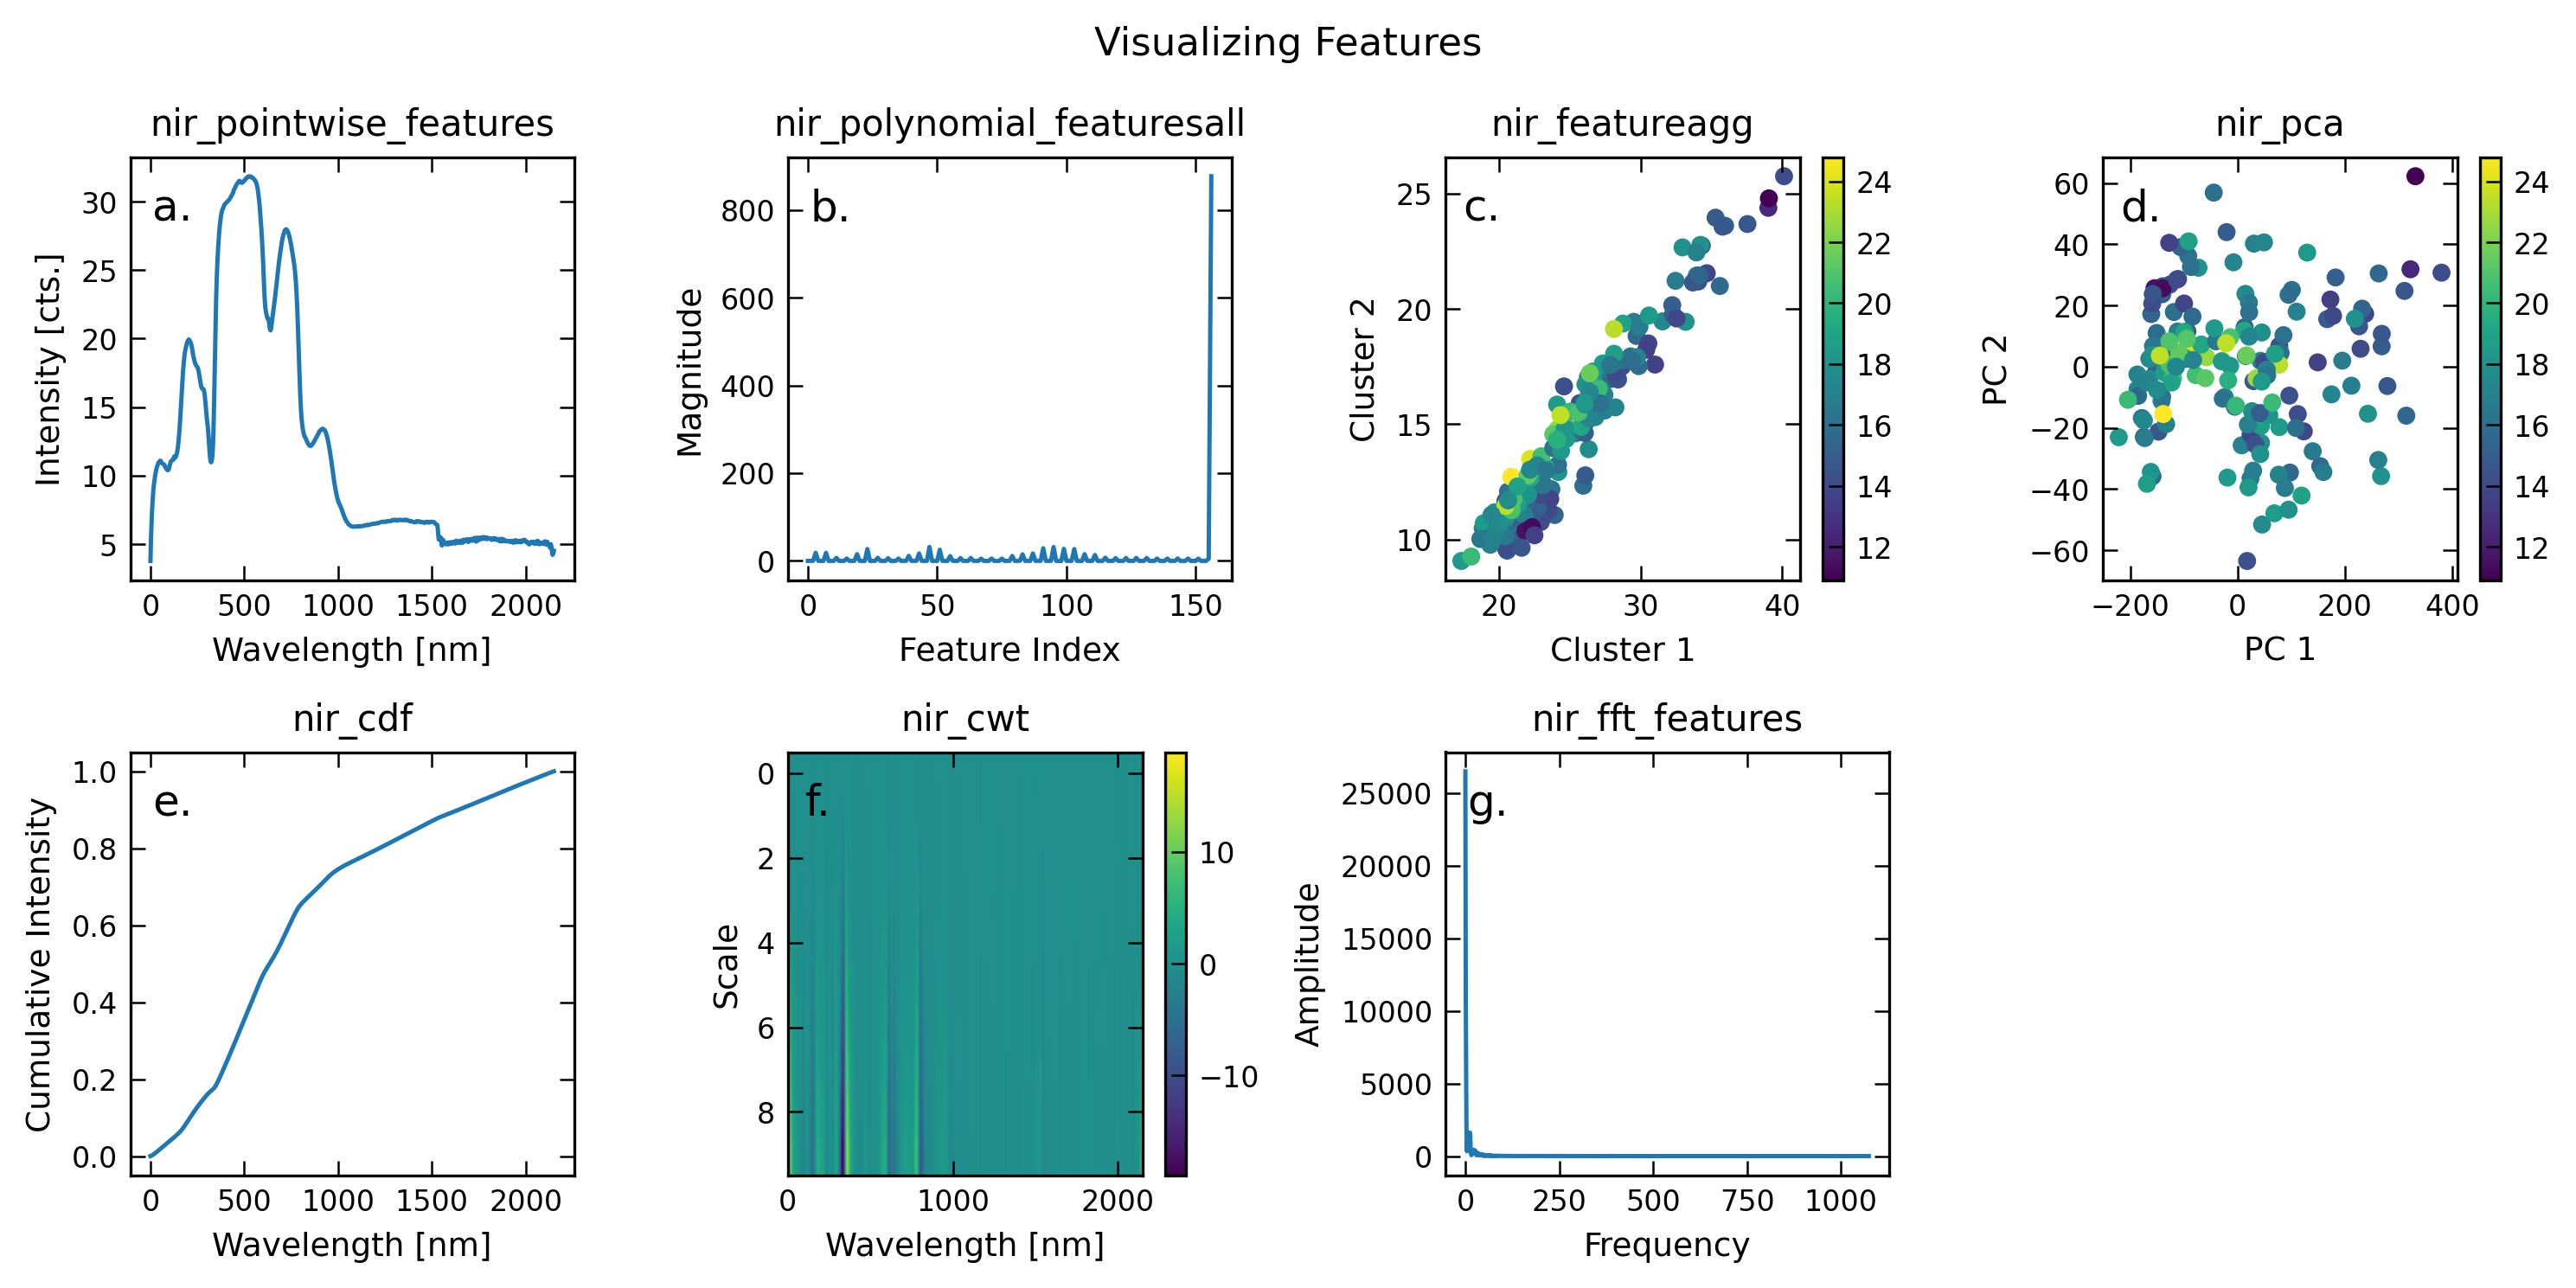

In [6]:
from spectrascope.SSPlotting import PlotSpectralFeatures
import string 

f, axs = plt.subplots(2,4, figsize=(10,5))
axs = axs.ravel()

xlabels = ['Wavelength [nm]', 'Feature Index', 'Cluster 1', 'PC 1', 'Wavelength [nm]', 'Wavelength [nm]', 'Frequency']
ylabels = ['Intensity [cts.]', 'Magnitude', 'Cluster 2', 'PC 2', 'Cumulative Intensity', 'Scale',  'Amplitude']

for i, feat in enumerate(ss.generated_features): 
    feat_arr = getattr(ss, feat)
    if 'cwt' in feat: 
        cwt_coefs = ss.nir_cwt[0]
        im = axs[i].imshow(cwt_coefs.reshape(10,len(ss.nir_xaxis)), aspect='auto', cmap='viridis',
                vmax=(np.abs(cwt_coefs)).max(), vmin=-(np.abs(cwt_coefs)).max())
        f.colorbar(im, ax=axs[i])
        axs[i].set_title(feat)
    if 'featureagg' in feat or 'pca' in feat: 
        im = axs[i].scatter(feat_arr[:,0], feat_arr[:,1], c = ss.br)
        f.colorbar(im, ax=axs[i])
        axs[i].set_title(feat)
    if 'pointwise' in feat or 'polynomial' in feat or 'cdf' in feat or 'fft' in feat: 
        axs[i].plot(np.arange(feat_arr.shape[1]), feat_arr[0])
        axs[i].set_title(feat)
    axs[i].set_xlabel(xlabels[i])
    axs[i].set_ylabel(ylabels[i])
    # add subplot label
    axs[i].text(0.05, 0.85, string.ascii_lowercase[i] +'.', transform=axs[i].transAxes, fontsize=12)

f.suptitle('Visualizing Features')
axs[-1].axis('off')

#### 3. Model Training 
Now that we have generated the features, we can set up the models for training. We will train both Random Forest and LCEN models on each feature. We will create hyperparameter grids to do cross-validation during the model training. The model training in ``SpectraScope`` can be accessed using ``SpectraScope.do_sk`` for ``Scikit-Learn`` models, ``SpectraScope.do_LCEN`` for then LCEN algorithm, or ``SpectraScope.do_all`` to simultaneously do feature generation and model trainiing in one step. For clarity here we will just use the ``do_sk`` and ``do_LCEN`` functions. 

The dictionaries defined here are for the ``sklearn.pipeline.Pipeline`` objects and ``SPA.main_SPA`` objects that are accessed in ``do_sk`` and ``do_LCEN`` respectively, which do the main cross-validation and model training. 

> NOTE : Here, we skip training to the cwt features because this generates many features and takes longer to train. 

In [7]:
rf_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50,100,200, 300], 
                                        'criterion':['squared_error'],
                                        'max_depth': [10,35, 50,None]},
                'refit':True,
                'metric':mean_squared_error}
        
lcen_kwargs = {'l1_ratio':[0.001, 0.01,0.1, 0.3, 0.5, 0.6, 0.99],
                        'K_fold':5, 
                        'cv_method':'Kfold', 
                        'alpha':5, 
                        'degree':[1],
                        'trans_type':'poly', 
                        'LCEN_cutoff':5e-5, 
                        'LCEN_interaction':False, 
                        'scale_X':True, 
                        'scale_y':True, 
                        'verbosity_level':1}

In [8]:
# Takes 2 min to run on Macbook Pro 2024 M4 Max
for feat in ss.generated_features: 
    if 'cwt' not in feat: 
        if lcen_available:
            ss.do_LCEN(feat, 'br', **lcen_kwargs)
        ss.do_sk(feat, 'br', **rf_kwargs) 

Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Test set : RMSE = 1.5645 | Mean relative error = 0.0757
Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Test set : RMSE = 1.2552 | Mean relative error = 0.0605
Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Test set : RMSE = 1.4813 | Mean relative error = 0.0676
Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Test set : RMSE = 1.5039 | Mean relative error = 0.0722
Completed model LCEN
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Test set : RMSE = 1.5382 | Mean relative error = 0.0745
Completed model LCEN
The best 

#### 4. Visualization of the Model Results 
Here we plot the % RMSE of the different model/feature combinations. What we can initially see is that in general, the LCEN algorithm performs better than the Random Forest, and that for both models, a few of the featurization schemes perform better than the raw data. This suggests that while many of these featurizations reduce the dimension of the data, the method of transformation still retains information about the prediction variable.

Text(557.3577777777779, 0.5, '% RMSE')

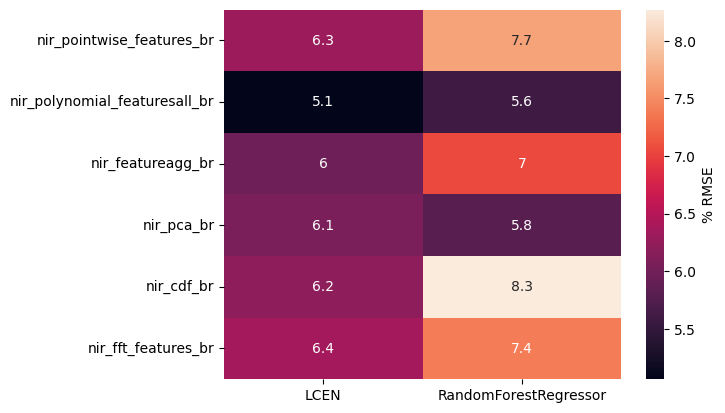

In [9]:
import seaborn as sns
sns.heatmap((np.sqrt(pd.DataFrame(ss.best_fits))) / np.max(ss.br) * 100, annot=True)
cbar = plt.gcf().axes[-1]
cbar.set_ylabel('% RMSE')

#### 5. Feature Importance
Finally, we will visualize the most important features for the best performing models. We will compare the raw spectral data with that of the polynomial featurization. 

a. The top 10 most important features selected by the Random Forest Regressor for the raw NIR data. The vertical blue lines correspond with the features (wavelength) selected. 

b. The top 10 most important features selected by the Random Forest Regressor for the polynomial transformation scheme of the NIR data. The characteristic polynomial images highlight which polynomial coefficient was selected as an important feature, and the position of the polynomial corresponds to the center of the bin from which it was fitted. 

c. The top 10 most important features selected by the LCEN model for the raw NIR data. The top 10 important features are those with the highest magnitude coefficient. The vertical blue lines correspond with the features (wavelength) selected. 

d. The top 10 most important features selected by the LCLEN model for the polynomial transformation scheme of the NIR data. The characteristic polynomial images highlight which polynomial coefficient was selected as an important feature, and the position of the polynomial corresponds to the center of the bin from which it was fitted. 

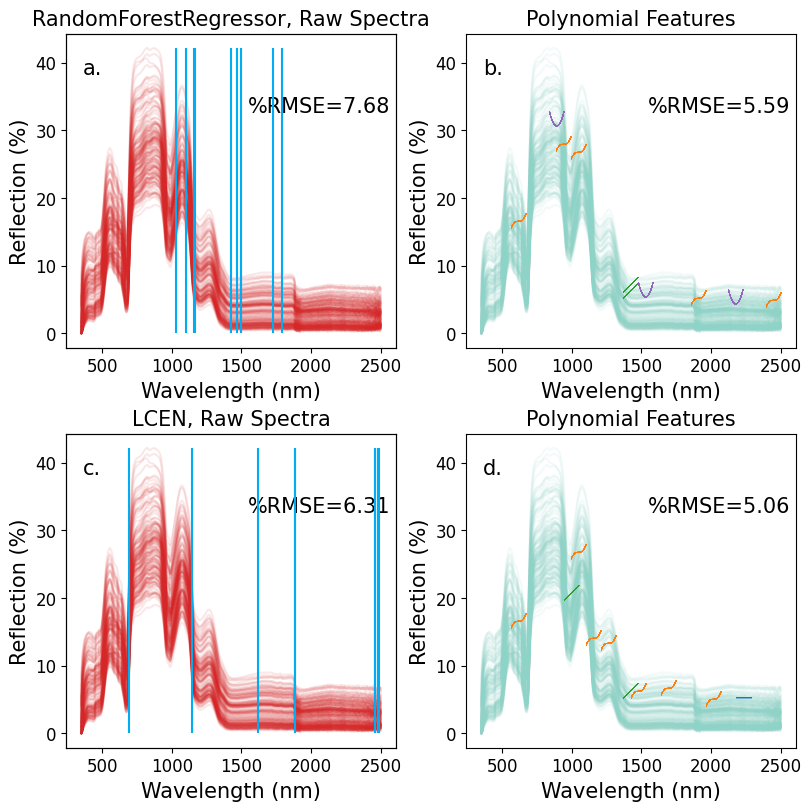

In [10]:
from spectrascope.SSPlotting import plot_spectral_features_matplotlib  
fontsize = 15
ticklabelsize = 12

f, ((ax1,ax2), (ax3,ax4)) = plt.subplots(2,2, figsize=(8,8), constrained_layout=True)
axs = axs.ravel()

models = ['RandomForestRegressor', 'LCEN']
for mn,ax in zip(models, [ax1, ax3]): 
    ax.set_title(f'{mn}, Raw Spectra', size=fontsize)
    for spec in ss.nir_pointwise_features: 
        ax.plot(ss.nir_xaxis, spec, color='#d62728', alpha=0.1)
    ax_twin = ax.twinx()
    model = getattr(ss, f'nir_pointwise_features_br_{mn}')
    selected_features = model['selected_features'][:10]
    selected_vals = model['selected_vals']
    for j in selected_features:
        ax_twin.vlines(ss.nir_xaxis[j], 0, 1, color='#00ADF2', alpha=1)
    ax_twin.set_yticks([])
    prmse = np.sqrt(ss.best_fits[mn]['nir_pointwise_features_br']) / np.max(ss.br) * 100
    ax.text(0.55,0.75, f'%RMSE={round(prmse,2)}', transform=ax.transAxes,fontsize=fontsize)

for mn, ax in zip(models, [ax2,ax4]):
    ax.set_title(f'Polynomial Features', size=fontsize)
    model = getattr(ss, f'nir_polynomial_featuresall_br_{mn}')
    prmse = np.sqrt(ss.best_fits[mn]['nir_polynomial_featuresall_br']) / np.max(ss.br) * 100
    ax.text(0.55,0.75, f'%RMSE={round(prmse,2)}', transform=ax.transAxes,fontsize=fontsize)

    for spec in ss.nir_pointwise_features: 
        ax.plot(ss.nir_xaxis, spec, color=plt.cm.Set3(np.arange(10))[0], alpha=0.1)
    plot_spectral_features_matplotlib(ss.nir_xaxis, ss.nir_pointwise_features[0], model['selected_features'][:10], ax=ax,zoom=0.03, plot_raw=False)

for i,ax in enumerate([ax1, ax2, ax3, ax4]):
    ax.set_xlabel('Wavelength (nm)',fontsize=fontsize)
    ax.set_ylabel('Reflection (%)',fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=ticklabelsize)
    ax.xaxis.label.set_size(fontsize)
    ax.yaxis.label.set_size(fontsize)
    ax.text(0.05, 0.87, string.ascii_lowercase[i] +'.', transform=ax.transAxes, fontsize=fontsize)